# Preranked GSEA

## Setup

Download a **MEME motif database file** containing human transcription factor binding motifs from the Cis-BP resource, alongside the **human genome** in fasta format.

In [ ]:
%%bash
[ -f data/cisBP_human.meme ] || wget -O data/cisBP_human.meme https://osf.io/download/uk6vn
[ -f data/GRCh38.fa ] || wget -O data/GRCh38.fa.gz https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_38/GRCh38.p13.genome.fa.gz
[ -f data/GRCh38.fa ] || gunzip -c data/GRCh38.fa.gz > data/GRCh38.fa

In [3]:
import gatac as ga
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sc.set_figure_params(dpi=100, frameon=False)

MOTIF_FILE = "data/cisBP_human.meme"
peak_adata = ad.read_h5ad("data/pbmc_peaks.h5ad")
# Get marker peaks for cluster 0
markers = ga.tl.marker_peaks(peak_adata, "leiden")
print("Available clusters:", list(markers.keys()))

15:43:10 - gatac.tl.markers - INFO - Running marker peak detection for groups in 'leiden'
15:43:10 - gatac.tl.markers - INFO - Testing 13 groups, 178,350 features, 5,001 cells
15:43:10 - gatac.tl.markers - INFO - Using max_cells=500 per group for balanced comparison
15:43:12 - gatac.tl.markers - INFO - Marker peak detection complete. Results stored in adata.uns['marker_peaks']


Available clusters: ['0', '1', '10', '11', '12', '2', '3', '4', '5', '6', '7', '8', '9']


## 1. Prepare ranked peak list

In [4]:
# Use cluster 0 markers ranked by log2 fold-change
cluster = "0"
marker_df = markers[cluster].sort_values("log2_fc", ascending=False)

# Build a DataFrame indexed by peak name with the expected column name
rankings = marker_df.set_index("feature")[["log2_fc"]].rename(columns={"log2_fc": "log2fc"})
print(f"Ranked {len(rankings):,} peaks for cluster {cluster}")


Ranked 5,575 peaks for cluster 0


## 2. Build motif gene sets

Map each motif to the set of peaks that contain that motif.

In [ ]:
motifs = ga.tl.read_motifs(MOTIF_FILE, unique=True)
ga.tl.scan_motifs(
    peak_adata,
    motifs=motifs,
    genome_fasta="data/GRCh38.fa",
)
motif_names = [m.name for m in motifs]
# Build gene sets: motif → list of peaks containing that motif
motif_matrix = peak_adata.varm["motif_match"]
import scipy.sparse as sp
peak_names = peak_adata.var_names.tolist()
motif_terms = {
    motif_names[j]: [peak_names[i] for i in motif_matrix[:, j].nonzero()[0]]
    for j in range(motif_matrix.shape[1])
    if motif_matrix[:, j].nnz > 0
}
print(f"Built {len(motif_terms)} motif gene sets")

15:43:18 - gatac.tl.chromvar - INFO - Scanning 1165 motifs in 178350 peaks...
15:43:18 - gatac.tl.chromvar - INFO - Using 0-based coordinate system
15:43:18 - gatac.tl.chromvar - INFO - Fetching sequences from genome...


Fetching sequences:   0%|          | 0/178350 [00:00<?, ?it/s]

15:43:20 - gatac.tl.chromvar - INFO - Background from sequences: A=0.2589 C=0.2412 G=0.2411 T=0.2588
15:43:20 - gatac.tl.chromvar - INFO - Computing score thresholds...


Computing thresholds:   0%|          | 0/1165 [00:00<?, ?it/s]

15:43:24 - gatac.tl.chromvar - INFO - Scanning motifs on GPU in 4 batch(es) of 50000 peaks...


Peak batches:   0%|          | 0/4 [00:00<?, ?it/s]

In [ ]:
motif_matrix = peak_adata.varm["motif_match"]
import scipy.sparse as sp
peak_names = peak_adata.var_names.tolist()
motif_terms = {
    motif_names[j]: [peak_names[i] for i in motif_matrix[:, j].nonzero()[0]]
    for j in range(motif_matrix.shape[1])
    if motif_matrix[:, j].nnz > 0
}
print(f"Built {len(motif_terms)} motif gene sets")

Built 1165 motif gene sets


## 3. Run preranked GSEA

In [25]:
import time

t0 = time.perf_counter()
gsea_df = ga.tl.gsea_motif_enrichment(
    peak_adata,
    rankings=rankings,
)
print(f"GSEA in {time.perf_counter() - t0:.1f}s")
gsea_df.nsmallest(10, "fdr")

17:24:26 - gatac.tl.motif - INFO - Built 1,165 motif feature sets (≥15 peaks; filter to ≥15)
17:24:26 - gatac.tl.motif - INFO - Running GSEA (gpu) on provided rankings...
17:24:27 - gatac.tl.gsea - INFO - GPU GSEA: 1137 feature sets, 5305 features, 1000 permutations  (gs_batch=4, perm_batch=256)
17:24:27 - gatac.tl.gsea - INFO - Generating permutation indices...


GSEA feature-set batches:   0%|          | 0/285 [00:00<?, ?it/s]

GSEA in 11.1s


,motif,NES,pval,fdr,lead_edge_n,set_size,lead_edge_frac
0,CEBPA,5.364148,0.0,0.0,107,315,0.339683
1,CEBPB,4.925610,0.0,0.0,66,160,0.412500
2,CEBPG,4.235527,0.0,0.0,59,129,0.457364
3,CEBPE,3.591549,0.0,0.0,41,101,0.405941
4,CEBPD,3.550723,0.0,0.0,42,113,0.371681
5,NFE2L2,3.454037,0.0,0.0,95,356,0.266854
6,BACH1,3.372003,0.0,0.0,96,360,0.266667
7,FOSL2,2.807798,0.0,0.0,86,345,0.249275
8,TEF,2.780295,0.0,0.0,33,94,0.351064
9,BACH2,2.765251,0.0,0.0,117,402,0.291045


## 4. GSEA enrichment plot

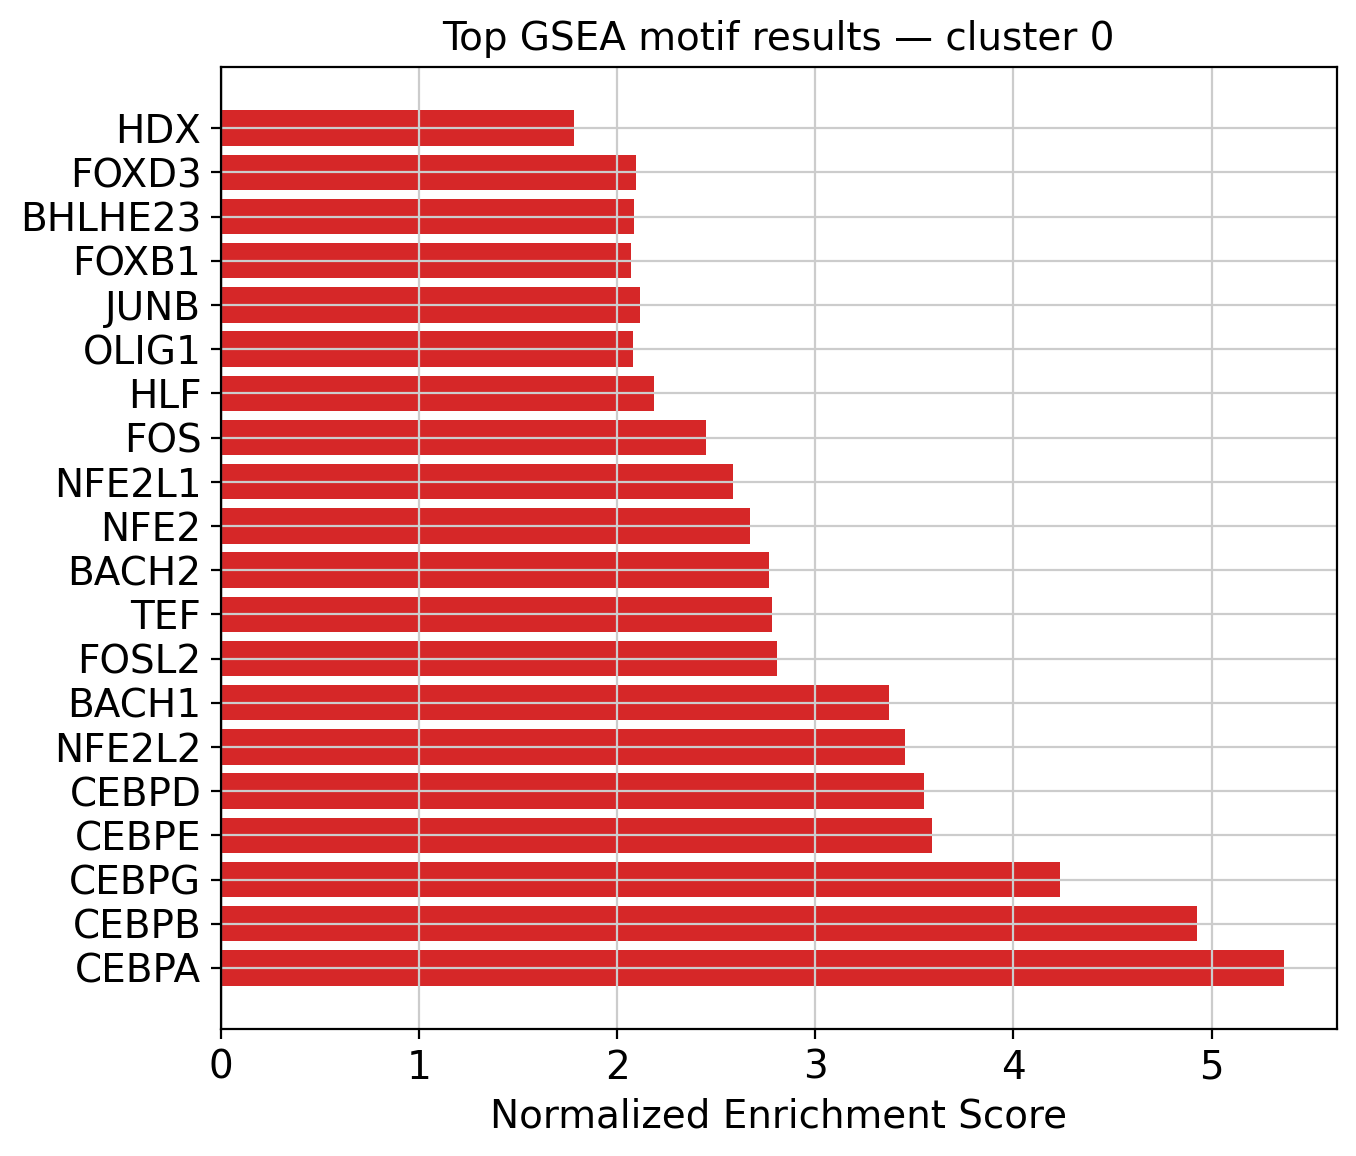

In [28]:
top_results = gsea_df.nsmallest(20, "fdr")

fig, ax = plt.subplots(figsize=(7, 6))
colors = ["#d62728" if nes > 0 else "#1f77b4" for nes in top_results["NES"]]
bars = ax.barh(range(len(top_results)), top_results["NES"], color=colors)
ax.set_yticks(range(len(top_results)))
ax.set_yticklabels(top_results["motif"])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Normalized Enrichment Score")
ax.set_title(f"Top GSEA motif results — cluster {cluster}")
plt.tight_layout()
plt.show()

## Next steps

- [API: `ga.tl.gsea_motif_enrichment`](../docs/api/tools.md#gsea-motif-enrichment)